In [1]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

import statsmodels.api as sm
from statsmodels.formula.api import mixedlm, ols
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 


%matplotlib inline

In [21]:
basedir = pathlib.Path("/media/mplitt/SSD_storage/2P_scratch/R18B05LexA_jGCaMP7b_EPGGal4_shiTS")

sess_df = pd.read_csv(basedir / 'sessions.csv')
print(sess_df.columns)
sess_df['fly_id'] = [row['date']+'_'+row['fly'] +'_' + row['condition'] for _, row in sess_df.iterrows()]


sess_df = sess_df.loc[sess_df['usable']==1]

figfolder = pathlib.Path("/media/mplitt/SSD_storage/fig_scratch/R18B05LexA_jGCaMP7b_EPGGal4_shiTS")
figfolder.mkdir(exist_ok=True, parents=True)

Index(['date', 'fly', 'sess', 'fictrac_scan_num', 'fictrac_file', 'condition',
       'scan_type', 'usable', 'notes'],
      dtype='str')


In [22]:
sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,usable,notes,fly_id
0,06_08_2026,fly1,baseline-001,1,fictrac-20260806_092051.dat,exp,baseline,1,NaN,06_08_2026_fly1_exp
1,06_08_2026,fly1,post_heat-002,2,fictrac-20260806_092051.dat,exp,post_heat,1,NaN,06_08_2026_fly1_exp
2,06_08_2026,fly2,baseline-000,0,fictrac-20260806_103458.dat,exp,baseline,1,NaN,06_08_2026_fly2_exp
3,06_08_2026,fly2,post_heat-002,2,fictrac-20260806_103458.dat,exp,post_heat,1,NaN,06_08_2026_fly2_exp
4,06_08_2026,fly5,baseline-000,0,fictrac-20260806_140412.dat,exp,baseline,1,NaN,06_08_2026_fly5_exp


In [23]:
def load_row(row):
    outdir = pathlib.PurePath( basedir / row['condition'] / row['date'] / row['fly'] / row['sess'] / 'preprocess.pkl')
    return st2p.preprocessing.EBImagingSession.from_file(outdir)

In [24]:
dh_bins = np.linspace(.0, 3.14, num=20)

stats_df = nmp.epg_silencing.rho_stats(sess_df, load_row, dh_bins=dh_bins)

grouped = stats_df.groupby(['fly_id','scan_type','condition'])['rho_dig'].apply(lambda x: np.nanmean(np.stack(x),axis=0))
grouped = grouped.reset_index()
grouped['rho_mean'] = grouped['rho_dig'].apply(lambda x: np.nanmean(x[3:]))

grouped.head()

,fly_id,scan_type,condition,rho_dig,rho_mean
0,06_08_2026_fly1_exp,baseline,exp,"[0.27046275967157446, 0.6868013359009687, 0.68...",0.788092
1,06_08_2026_fly1_exp,post_heat,exp,"[0.14052356581420863, 0.1359960134281424, 0.13...",0.141171
2,06_08_2026_fly1_gal4_only,baseline,gal4_only,"[0.21503216833126176, 0.2959966963305773, 0.30...",0.385068
3,06_08_2026_fly1_gal4_only,post_heat,gal4_only,"[0.3182495994429298, 0.34632788611477255, 0.38...",0.324253
4,06_08_2026_fly2_exp,baseline,exp,"[0.1778933750249806, 0.37546856174307786, 0.43...",0.592469


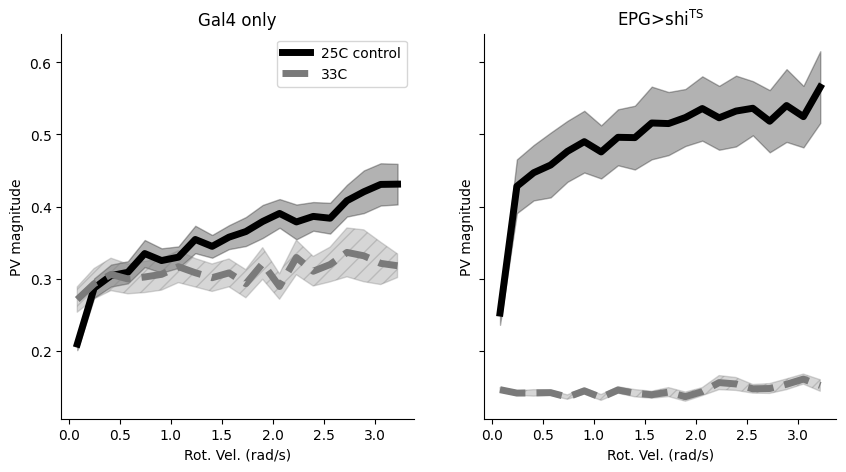

In [25]:
dh_bin_centers = dh_bins+np.diff(dh_bins)[0]/2
conditions = ('exp','gal4_only') 
rho_dict = {}
for cond in conditions:
    rho_dict[cond] = {'baseline_rho':[],
                      'heat_rho':[]}

for fly in grouped['fly_id'].unique():
    if (grouped['fly_id']==fly).sum()>1:
        
        cond = grouped.loc[grouped['fly_id']==fly,'condition'].iloc[0]
        
        baseline_rho = grouped.loc[(grouped['fly_id']==fly) * (grouped['scan_type']=='baseline'), 'rho_dig']
        heat_rho = grouped.loc[(grouped['fly_id']==fly) * (grouped['scan_type']=='post_heat'), 'rho_dig']
        
        
        rho_dict[cond]['baseline_rho'].append(baseline_rho.iloc[0])
        rho_dict[cond]['heat_rho'].append(heat_rho.iloc[0])

for cond in conditions:
    # if cond not in ['vacht_rnai']:
        rho_dict[cond]['baseline_rho'] = np.stack(rho_dict[cond]['baseline_rho'])
        rho_dict[cond]['heat_rho'] = np.stack(rho_dict[cond]['heat_rho'])



fig, ax= plt.subplots(1,2, figsize=[10,5], sharey=True)
mu,sem = np.nanmean(rho_dict['gal4_only']['baseline_rho'],axis=0), sp.stats.sem(rho_dict['gal4_only']['baseline_rho'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color='black', linewidth=5, label='25C control')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(rho_dict['gal4_only']['heat_rho'],axis=0), sp.stats.sem(rho_dict['gal4_only']['heat_rho'],axis=0,nan_policy='omit')
ax[0].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label ='33C', linestyle='--')
ax[0].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')




mu,sem = np.nanmean(rho_dict['exp']['baseline_rho'],axis=0), sp.stats.sem(rho_dict['exp']['baseline_rho'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color='black', linewidth=5, label='25C control')
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color='black', alpha=.3)


mu,sem = np.nanmean(rho_dict['exp']['heat_rho'],axis=0), sp.stats.sem(rho_dict['exp']['heat_rho'],axis=0,nan_policy='omit')
ax[1].plot(dh_bin_centers, mu, color=plt.cm.Greys(.6), linewidth=5, label ='33C', linestyle='--')
ax[1].fill_between(dh_bin_centers, mu-sem, mu+sem, color=plt.cm.Greys(.6), alpha=.3, hatch='//')

ax[0].legend()



for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xlabel('Rot. Vel. (rad/s)')
    a.set_ylabel('PV magnitude')
ax[0].set_title('Gal4 only')
ax[1].set_title(r"EPG>$\mathregular{shi^{TS}}$")

fig.savefig(figfolder / 'PVMag_v_RotVel.pdf', format='pdf')
    

In [26]:
dh_bin_centers 

array([0.08263158, 0.24789474, 0.41315789, 0.57842105, 0.74368421,
       0.90894737, 1.07421053, 1.23947368, 1.40473684, 1.57      ,
       1.73526316, 1.90052632, 2.06578947, 2.23105263, 2.39631579,
       2.56157895, 2.72684211, 2.89210526, 3.05736842, 3.22263158])

In [27]:
grouped.head()

,fly_id,scan_type,condition,rho_dig,rho_mean
0,06_08_2026_fly1_exp,baseline,exp,"[0.27046275967157446, 0.6868013359009687, 0.68...",0.788092
1,06_08_2026_fly1_exp,post_heat,exp,"[0.14052356581420863, 0.1359960134281424, 0.13...",0.141171
2,06_08_2026_fly1_gal4_only,baseline,gal4_only,"[0.21503216833126176, 0.2959966963305773, 0.30...",0.385068
3,06_08_2026_fly1_gal4_only,post_heat,gal4_only,"[0.3182495994429298, 0.34632788611477255, 0.38...",0.324253
4,06_08_2026_fly2_exp,baseline,exp,"[0.1778933750249806, 0.37546856174307786, 0.43...",0.592469


In [28]:
rho_plot_df = []
fly_ids = grouped['fly_id'].unique()

for fly_id in fly_ids:
    fly_df = grouped.loc[grouped['fly_id']==fly_id]

    baseline_rho = fly_df.loc[fly_df['scan_type']=='baseline','rho_mean'].iloc[0]
    heat_rho = fly_df.loc[fly_df['scan_type']=='post_heat','rho_mean'].iloc[0]
    rho_plot_df.append({
        'fly_id':fly_id, 
        'baseline_rho':baseline_rho, 
        'heat_rho':heat_rho, 
        'condition':fly_df['condition'].iloc[0]
        })
rho_plot_df = pd.DataFrame(rho_plot_df)

12 10


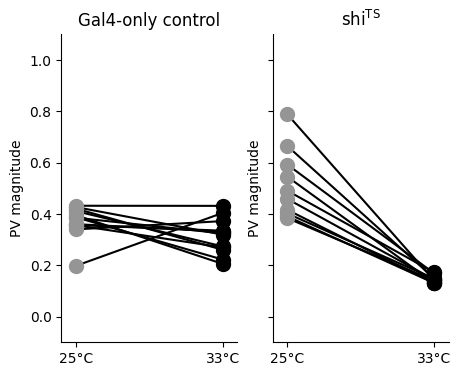

In [39]:
fig,ax = plt.subplots(1,2,sharey=True, figsize=[5,4])

c_df = rho_plot_df.loc[rho_plot_df['condition']=='exp']
ax[1].set_title(r"$\mathregular{shi^{TS}}$")

ax[1].plot([0,1], c_df[['baseline_rho', 'heat_rho']].T, color='black', zorder=-1)
ax[1].scatter(np.zeros((c_df.shape[0],)), c_df['baseline_rho'], color=plt.cm.Greys(.5), alpha=1, s=100)
ax[1].scatter(np.ones((c_df.shape[0],)), c_df['heat_rho'], color='black', alpha=1, s=100)

gal4_df = rho_plot_df.loc[rho_plot_df['condition']=='gal4_only']
ax[0].set_title('Gal4-only control')

ax[0].plot([0,1], gal4_df[['baseline_rho', 'heat_rho']].T, color='black', zorder=-1)
ax[0].scatter(np.zeros((gal4_df.shape[0],)), gal4_df['baseline_rho'], color=plt.cm.Greys(.5), alpha=1, s=100)
ax[0].scatter(np.ones((gal4_df.shape[0],)), gal4_df['heat_rho'], color='black', alpha=1, s=100)



for _ax in ax:
    _ax.set_ylim([-0.1,1.1])
    _ax.set_xlim([-.1,1.1])
    _ax.set_yticks([0,.2,.4,.6,.8,1.])

    _ax.set_xticks([0, 1], labels=['25°C', '33°C'])
    _ax.set_ylabel('PV magnitude')
    _ax.spines['top'].set_visible(False)
    _ax.spines['right'].set_visible(False)
    
# ax[0].set_ylabel('offset vector length')
# fig.suptitle('OctAlpha2R KO')
print(gal4_df.shape[0], c_df.shape[0])

fig.savefig(figfolder / 'offset_mag_summary.pdf', format='pdf')


In [30]:
import pingouin as pg
from pingouin import mixed_anova, pairwise_tests
aov = mixed_anova(dv='rho_mean', between='condition',
                  within='scan_type', subject='fly_id', data=grouped)
aov

,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition,0.001853,1,20,0.001853,0.317994,5.790848e-01,0.015651,NaN
1,scan_type,0.439228,1,20,0.439228,60.718944,1.746119e-07,0.752227,1.0
2,Interaction,0.258360,1,20,0.258360,35.715792,7.631243e-06,0.641035,NaN


In [31]:
tt = pairwise_tests(dv='rho_mean', between='condition',
                   subject='fly_id', within='scan_type', data=grouped,
                   padjust='holm', parametric=False, interaction=True, within_first=False)

print(tt['Contrast'].unique())
pvals_0 = tt['p_unc'].iloc[-2:]
tt

['condition' 'scan_type' 'condition * scan_type']


,Contrast,condition,A,B,Paired,Parametric,U_val,W_val,alternative,p_unc,p_corr,p_adjust,hedges
0,condition,-,exp,gal4_only,False,False,44.0,NaN,two-sided,0.306762,NaN,NaN,-0.232283
1,scan_type,-,baseline,post_heat,True,False,NaN,16.0,two-sided,0.000081,NaN,NaN,1.761198
2,condition * scan_type,exp,baseline,post_heat,True,False,NaN,0.0,two-sided,0.001953,0.003906,holm,3.678504
3,condition * scan_type,gal4_only,baseline,post_heat,True,False,NaN,16.0,two-sided,0.077148,0.077148,holm,0.874823


In [32]:
tt = pairwise_tests(dv='rho_mean', between='condition',
                   subject='fly_id', within='scan_type', data=grouped,
                   padjust='holm', parametric=False, interaction=True, within_first=True)

print(tt['Contrast'].unique())
pvals_1 = tt['p_unc'].iloc[-2:]
tt


['scan_type' 'condition' 'scan_type * condition']


,Contrast,scan_type,A,B,Paired,Parametric,U_val,W_val,alternative,p_unc,p_corr,p_adjust,hedges
0,scan_type,-,baseline,post_heat,True,False,NaN,16.0,two-sided,0.000081,NaN,NaN,1.761198
1,condition,-,exp,gal4_only,False,False,44.0,NaN,two-sided,0.306762,NaN,NaN,-0.232283
2,scan_type * condition,baseline,exp,gal4_only,False,False,101.0,NaN,two-sided,0.007574,0.007574,holm,1.333923
3,scan_type * condition,post_heat,exp,gal4_only,False,False,0.0,NaN,two-sided,0.000087,0.000175,holm,-3.067905


In [33]:
reject, pvals_corrected = pg.multicomp(pd.concat([pvals_0, pvals_1]), alpha=0.05, method='bonferroni')

In [34]:
reject, pvals_corrected

(array([ True, False,  True,  True]),
 array([0.0078125 , 0.30859375, 0.03029617, 0.00034936]))

In [35]:
sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,usable,notes,fly_id
0,06_08_2026,fly1,baseline-001,1,fictrac-20260806_092051.dat,exp,baseline,1,NaN,06_08_2026_fly1_exp
1,06_08_2026,fly1,post_heat-002,2,fictrac-20260806_092051.dat,exp,post_heat,1,NaN,06_08_2026_fly1_exp
2,06_08_2026,fly2,baseline-000,0,fictrac-20260806_103458.dat,exp,baseline,1,NaN,06_08_2026_fly2_exp
3,06_08_2026,fly2,post_heat-002,2,fictrac-20260806_103458.dat,exp,post_heat,1,NaN,06_08_2026_fly2_exp
4,06_08_2026,fly5,baseline-000,0,fictrac-20260806_140412.dat,exp,baseline,1,NaN,06_08_2026_fly5_exp


/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/shibirets.py:18: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  with vector length statistics for each condition.


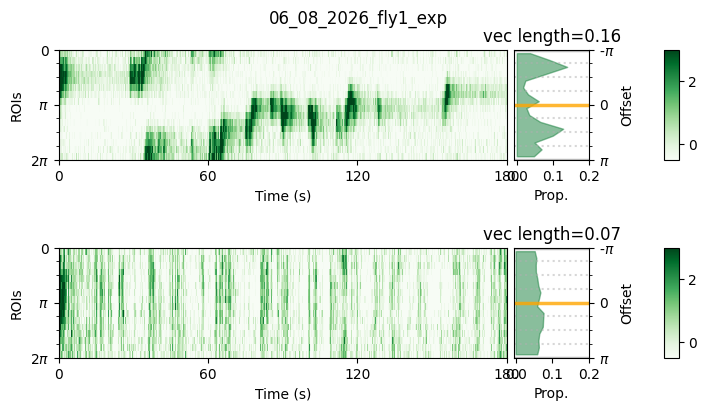

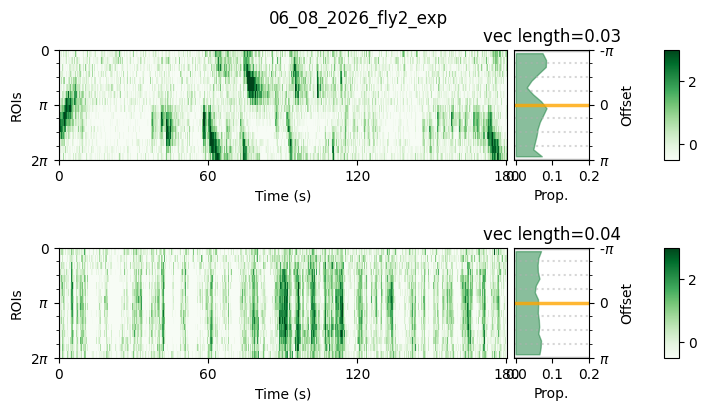

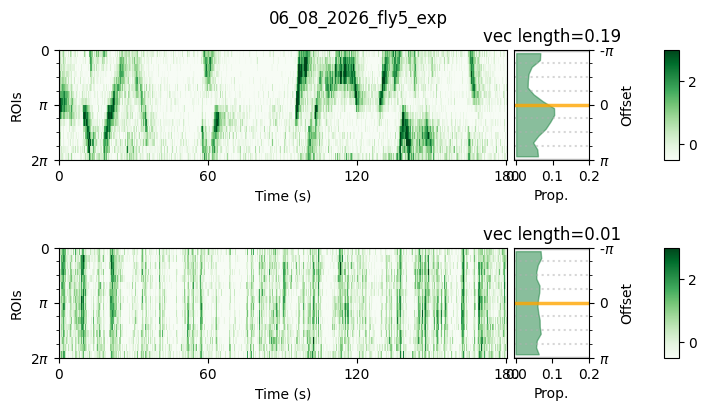

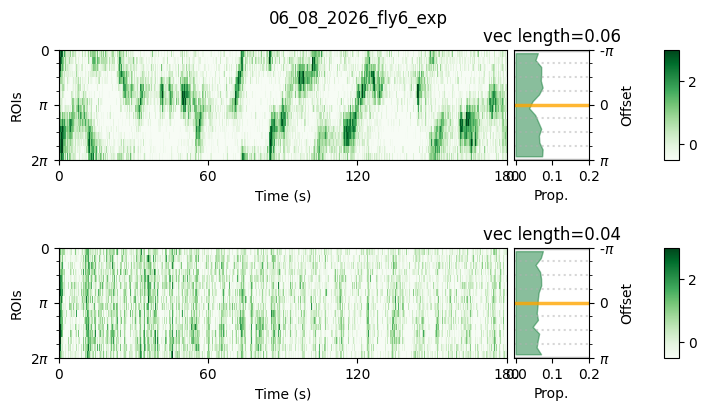

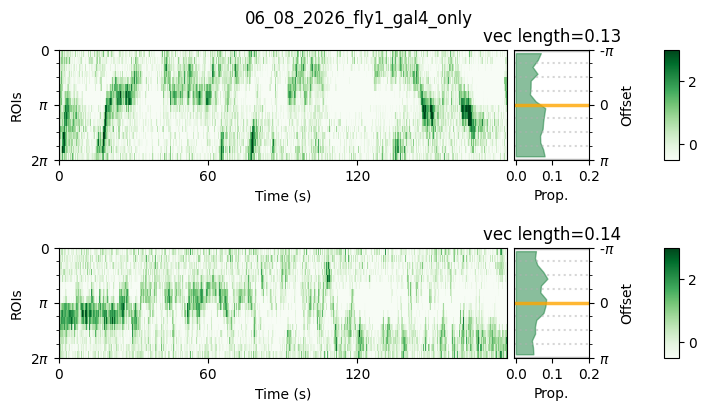

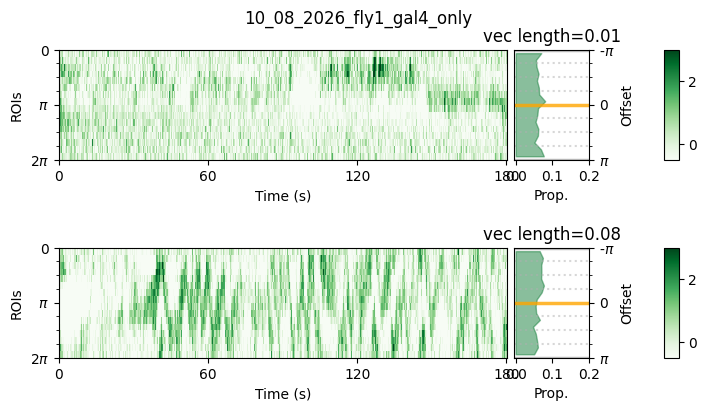

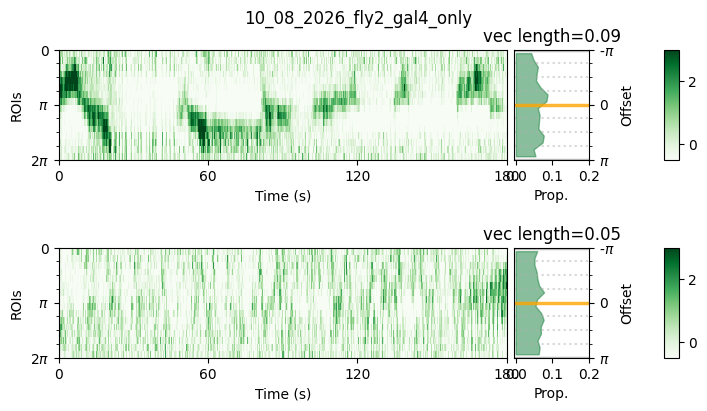

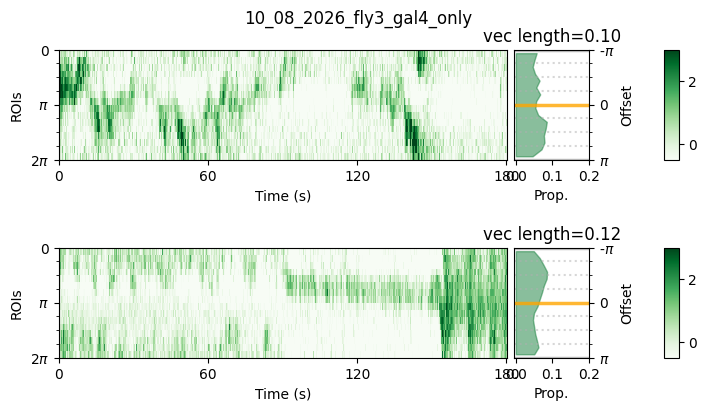

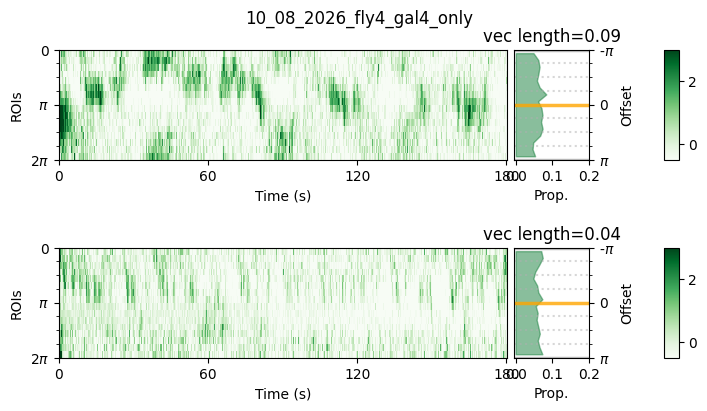

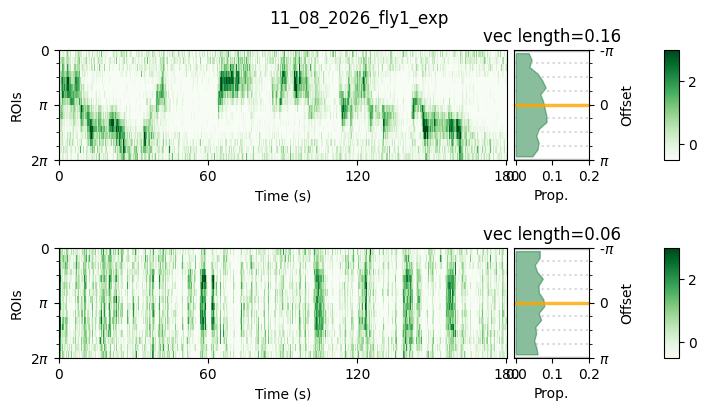

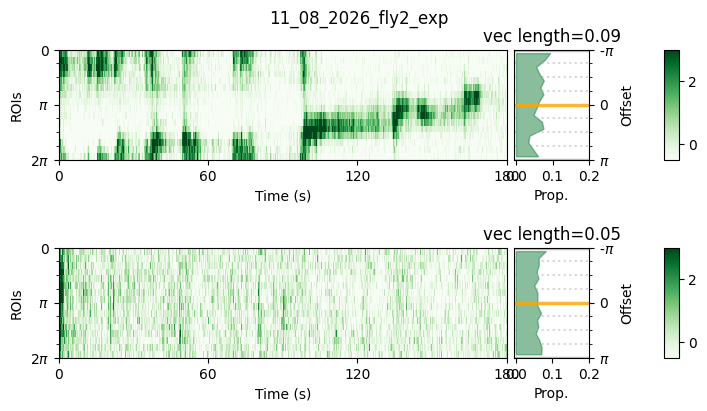

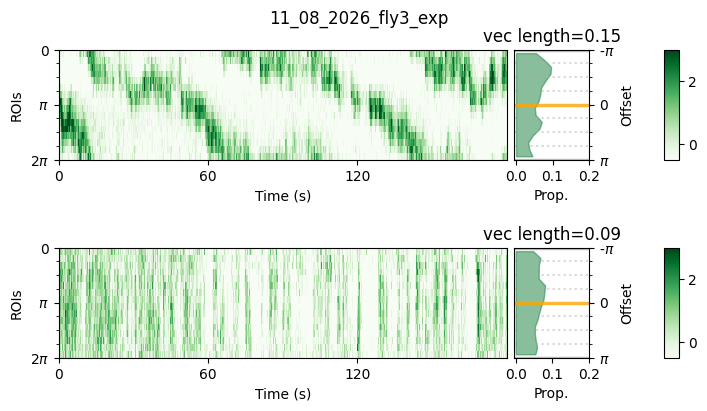

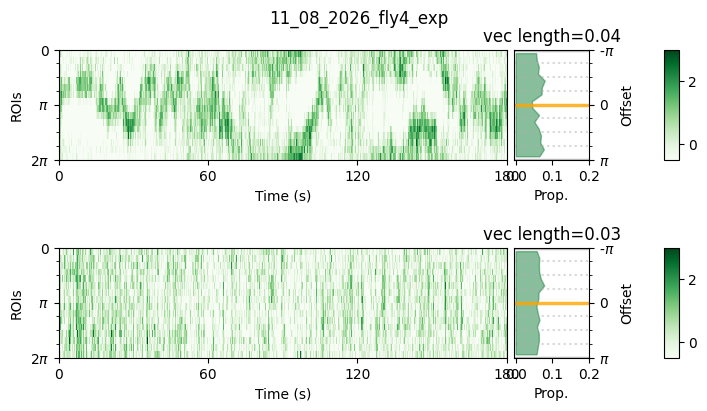

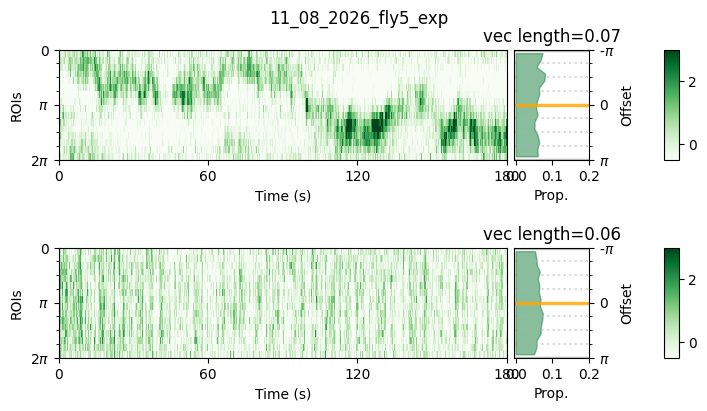

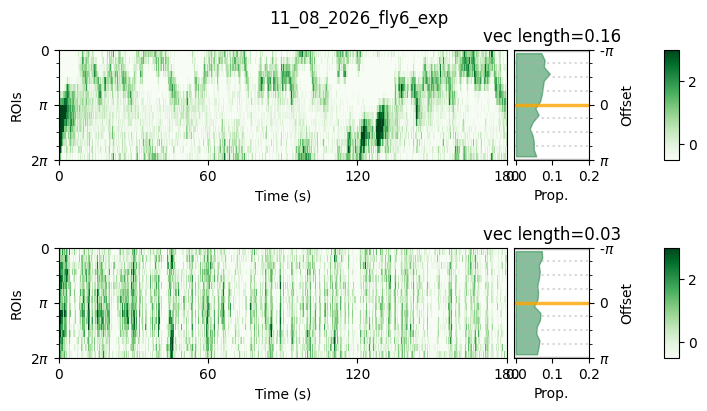

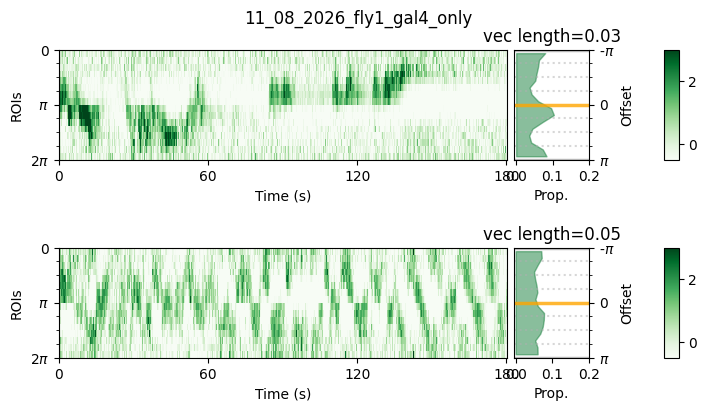

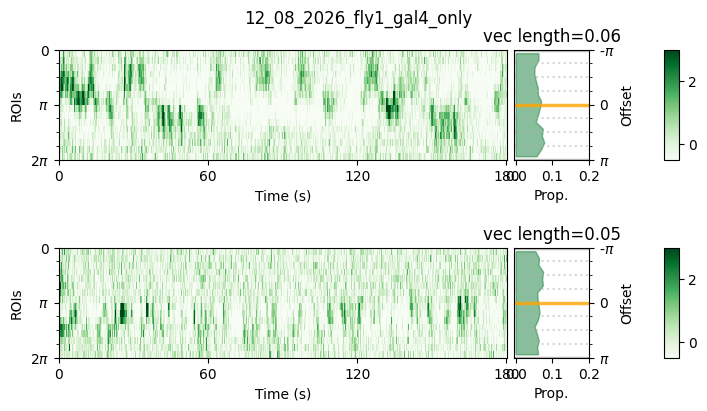

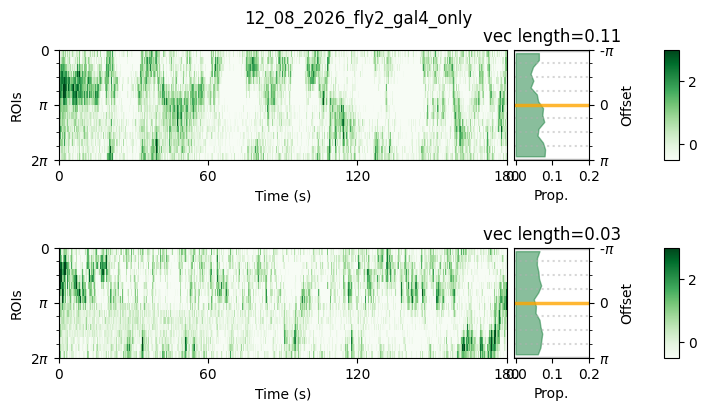

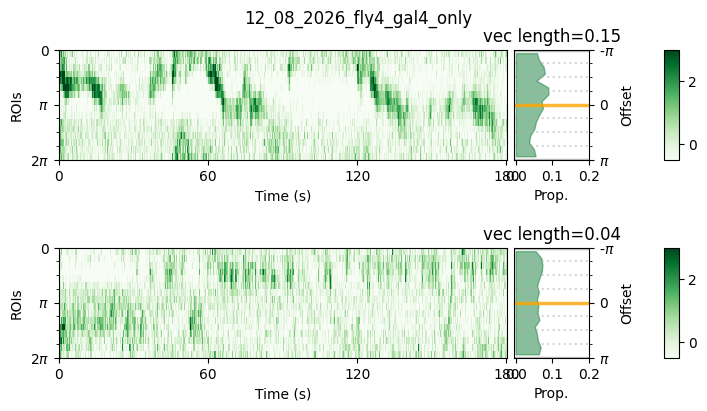

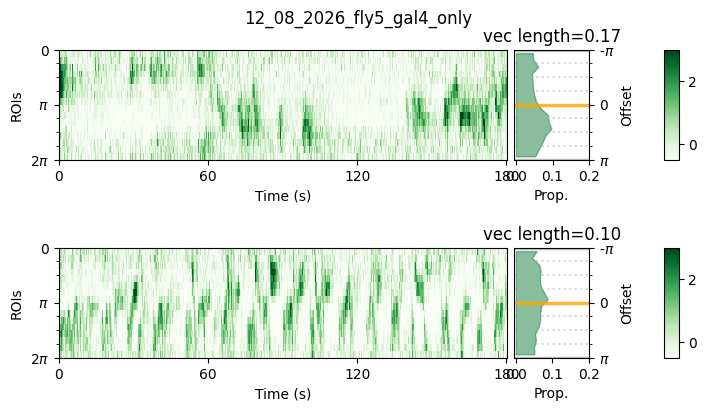

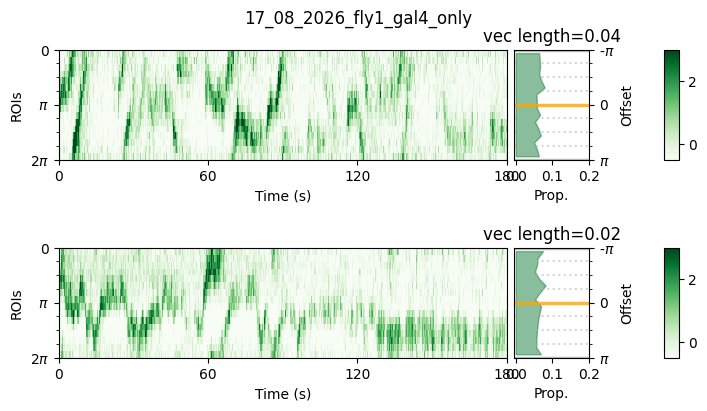

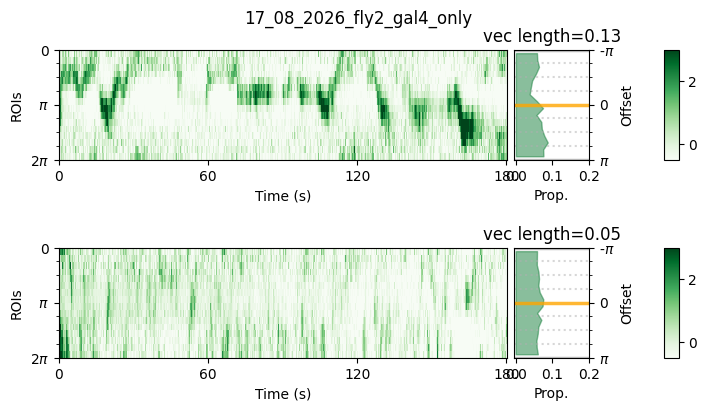

In [38]:
session_folder = figfolder / "sessions"
session_folder.mkdir(parents=True, exist_ok=True)

flies = sess_df['fly_id'].unique()
for fly in flies:
    
    baseline = sess_df.loc[(sess_df['fly_id']==fly) * (sess_df['scan_type']=='baseline')]
    heat = sess_df.loc[(sess_df['fly_id']==fly) * (sess_df['scan_type']=='post_heat')]
    
    if baseline.shape[0]>0 and heat.shape[0]>0:
        
        ts_dict = {'fly': fly,
                   'baseline': nmp.session.GetTS(load_row(baseline.iloc[0])),
                   'post_heat': nmp.session.GetTS(load_row(heat.iloc[0])),
        }
        
        fig_heatmaps, ax_heatmas = nmp.shibirets.plot_sess_heatmaps_w_hist(ts_dict, twindow=[0,180.1])
       
    
        fly_folder = session_folder / fly
        fly_folder.mkdir(parents=True, exist_ok=True)
        
        fig_heatmaps.savefig(fly_folder / "heatmaps.pdf")